In [1]:
import pandas as pd

In [2]:
dataset = pd.read_csv("Placement.csv")
dataset

,sl_no,gender,ssc_p,ssc_b,hsc_p,hsc_b,hsc_s,degree_p,degree_t,workex,etest_p,specialisation,mba_p,status,salary
0,1,M,67.00,Others,91.00,Others,Commerce,58.00,Sci&Tech,No,55.0,Mkt&HR,58.80,Placed,270000.0
1,2,M,79.33,Central,78.33,Others,Science,77.48,Sci&Tech,Yes,86.5,Mkt&Fin,66.28,Placed,200000.0
2,3,M,65.00,Central,68.00,Central,Arts,64.00,Comm&Mgmt,No,75.0,Mkt&Fin,57.80,Placed,250000.0
3,4,M,56.00,Central,52.00,Central,Science,52.00,Sci&Tech,No,66.0,Mkt&HR,59.43,Not Placed,NaN
4,5,M,85.80,Central,73.60,Central,Commerce,73.30,Comm&Mgmt,No,96.8,Mkt&Fin,55.50,Placed,425000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
210,211,M,80.60,Others,82.00,Others,Commerce,77.60,Comm&Mgmt,No,91.0,Mkt&Fin,74.49,Placed,400000.0
211,212,M,58.00,Others,60.00,Others,Science,72.00,Sci&Tech,No,74.0,Mkt&Fin,53.62,Placed,275000.0
212,213,M,67.00,Others,67.00,Others,Commerce,73.00,Comm&Mgmt,Yes,59.0,Mkt&Fin,69.72,Placed,295000.0
213,214,F,74.00,Others,66.00,Others,Commerce,58.00,Comm&Mgmt,No,70.0,Mkt&HR,60.23,Placed,204000.0


In [3]:
dataset.isna().sum()

sl_no              0
gender             0
ssc_p              0
ssc_b              0
hsc_p              0
hsc_b              0
hsc_s              0
degree_p           0
degree_t           0
workex             0
etest_p            0
specialisation     0
mba_p              0
status             0
salary            67
dtype: int64

**1)Replace the NaN values with correct value. And justify why you have
chosen the same.**

In [4]:
dataset["salary"] = dataset["salary"].fillna(0,inplace=True)

C:\Users\abina_a2cu98a\AppData\Local\Temp\ipykernel_2420\3099414268.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  dataset["salary"] = dataset["salary"].fillna(0,inplace=True)


In [5]:
dataset

,sl_no,gender,ssc_p,ssc_b,hsc_p,hsc_b,hsc_s,degree_p,degree_t,workex,etest_p,specialisation,mba_p,status,salary
0,1,M,67.00,Others,91.00,Others,Commerce,58.00,Sci&Tech,No,55.0,Mkt&HR,58.80,Placed,270000.0
1,2,M,79.33,Central,78.33,Others,Science,77.48,Sci&Tech,Yes,86.5,Mkt&Fin,66.28,Placed,200000.0
2,3,M,65.00,Central,68.00,Central,Arts,64.00,Comm&Mgmt,No,75.0,Mkt&Fin,57.80,Placed,250000.0
3,4,M,56.00,Central,52.00,Central,Science,52.00,Sci&Tech,No,66.0,Mkt&HR,59.43,Not Placed,0.0
4,5,M,85.80,Central,73.60,Central,Commerce,73.30,Comm&Mgmt,No,96.8,Mkt&Fin,55.50,Placed,425000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
210,211,M,80.60,Others,82.00,Others,Commerce,77.60,Comm&Mgmt,No,91.0,Mkt&Fin,74.49,Placed,400000.0
211,212,M,58.00,Others,60.00,Others,Science,72.00,Sci&Tech,No,74.0,Mkt&Fin,53.62,Placed,275000.0
212,213,M,67.00,Others,67.00,Others,Commerce,73.00,Comm&Mgmt,Yes,59.0,Mkt&Fin,69.72,Placed,295000.0
213,214,F,74.00,Others,66.00,Others,Commerce,58.00,Comm&Mgmt,No,70.0,Mkt&HR,60.23,Placed,204000.0


#Students who are not placed do not have a salary value, so the missing (NaN) values are replaced with 0

**2)How many of them are not placed?**

In [6]:
dataset[dataset['status']== "Not Placed"].groupby('status')['gender'].count()

status
Not Placed    67
Name: gender, dtype: int64

#67 students are not placed

**3)Find the reason for non placement from the dataset?**

In [7]:
dataset.groupby('status')[['ssc_p', 'hsc_p', 'degree_p',
                           'etest_p', 'mba_p']].mean()

,ssc_p,hsc_p,degree_p,etest_p,mba_p
status,,,,,
Not Placed,57.544030,58.395522,61.134179,69.587910,61.612836
Placed,71.721486,69.926554,68.740541,73.238041,62.579392


#Based on academic performance, we can identify factors that may explain why some students were not placed.

**4)What kind of relation between salary and mba_p?**

In [8]:
placed = dataset[dataset['status'] == 'Placed']

placed[["mba_p", "salary"]].corr()

,mba_p,salary
mba_p,1.000000,0.175013
salary,0.175013,1.000000


#There is a weak positive correlation (0.175) between MBA percentage (mba_p) and salary.

**5) which specialization is getting minimum salary**

In [9]:
dataset[dataset['salary'] != 0].groupby('specialisation')[['salary']].min()

,salary
specialisation,
Mkt&Fin,200000.0
Mkt&HR,200000.0


#Both Mkt&Fin and Mkt&HR getting minimum salary 200000

**6) How many of them getting above 500000 salary?**

In [10]:
count = 0
for salary in dataset['salary']:
   if salary > 500000:
      count += 1
print(count)

3


#Three students getting above 500000 salary

**7)Test the Analysis of Variance between etest_p and mba_p at signifance
level 5%.(Make decision using Hypothesis Testing)**

In [11]:
from scipy.stats import ttest_rel

ttest_rel(dataset['etest_p'], dataset['mba_p'])


TtestResult(statistic=np.float64(10.840680769176654), pvalue=np.float64(4.1449406968814713e-22), df=np.int64(214))

#The p-value is 4.145, which is not less than the 5% significance level (0.05). 
#Therefore, we reject the Null Hypothesis (H0) and accept the Alternative Hypothesis (H1).

**8)Test the similarity between the degree_t(Sci&Tech) and specialisa
tion(Mkt&HR) with respect to salary at significance level of 5%.(Make
decision using Hypothesis Testing**

In [12]:
from scipy.stats import ttest_ind
dataset = dataset.dropna()
degree = dataset[dataset['degree_t'] == 'Sci&Tech']['salary']
specialisation = dataset[dataset['specialisation'] == 'Mkt&HR']['salary']
ttest_ind(degree,specialisation)

TtestResult(statistic=np.float64(2.692041243555374), pvalue=np.float64(0.007897969943471191), df=np.float64(152.0))

#The p-value is 0.00789, which is less than the 5% significance level (0.05). 
#Therefore, we accept the Null Hypothesis (H0).

**9)Convert the normal distribution to standard normal distribution for salary column**

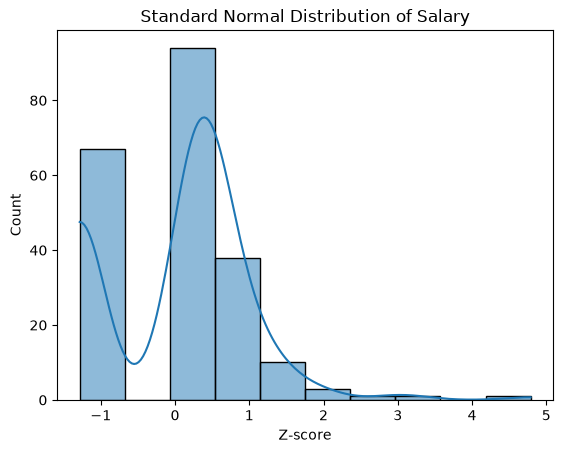

np.float64(-7.126082669687051e-17)

In [13]:
def stdNBgraph(dataset):
    import seaborn as sns
    import matplotlib.pyplot as plt
    mean = dataset.mean()
    std = dataset.std()
    z_score = [(j - mean) / std for j in dataset]
    sns.histplot(z_score, kde=True)
    plt.title("Standard Normal Distribution of Salary")
    plt.xlabel("Z-score")
    plt.show()
    return sum(z_score) / len(z_score)

stdNBgraph(dataset['salary'])

#The salary values are converted into Z-scores, with a mean of 0 and standard deviation of 1, to represent the standard normal distribution.

**10)What is the probability Density Function of the salary range from 700000 to 900000?**

In [14]:
def get_pdf_probability(dataset,startrange,endrange):
    from matplotlib import pyplot
    from scipy.stats import norm
    import seaborn as sns
    ax = sns.distplot(dataset,kde=True,kde_kws={'color':'blue'},color='Green')
    pyplot.axvline(startrange,color='Red')
    pyplot.axvline(endrange,color='Red')
    # generate a sample
    sample = dataset
    # calculate parameters
    sample_mean =sample.mean()
    sample_std = sample.std()
    print('Mean=%.3f, Standard Deviation=%.3f' % (sample_mean, sample_std))
    # define the distribution
    dist = norm(sample_mean, sample_std)
    
    # sample probabilities for a range of outcomes
    values = [value for value in range(startrange, endrange)]
    probabilities = [dist.pdf(value) for value in values]    
    prob=sum(probabilities)
    print("The area between range({},{}):{}".format(startrange,endrange,sum(probabilities)))
    return prob
    

C:\Users\abina_a2cu98a\AppData\Local\Temp\ipykernel_2420\2842244316.py:5: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  ax = sns.distplot(dataset,kde=True,kde_kws={'color':'blue'},color='Green')


Mean=198702.326, Standard Deviation=154780.927
The area between range(700000,900000):0.0005973310593974868


np.float64(0.0005973310593974868)

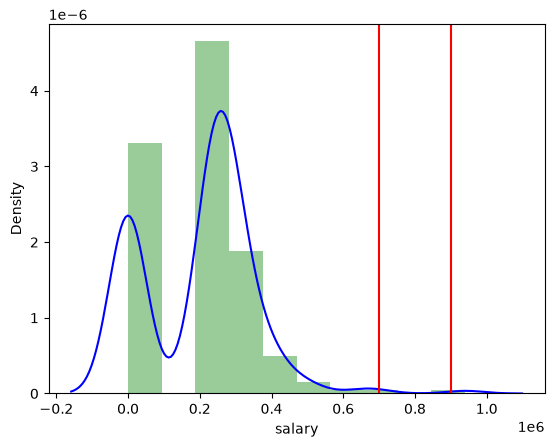

In [15]:
get_pdf_probability(dataset["salary"],700000,900000)

#The probability of salary falling between ₹7,00,000 and ₹9,00,000 is approximately 0.000597 (0.0597%).

#This indicates that only a very small proportion of salaries are expected to fall within this range, assuming the salary follows a normal distribution with the given mean and standard deviation.

**11)Test the similarity between the degree_t(Sci&Tech)with respect to 
etest_p and mba_p at significance level of 5%.(Make decision using Hypothesis Testing)**

In [16]:
from scipy.stats import ttest_rel
degree = dataset[dataset['degree_t'] == 'Sci&Tech']['etest_p']
degree1 = dataset[dataset['degree_t'] == 'Sci&Tech']['mba_p']
ttest_rel(degree,degree1)

TtestResult(statistic=np.float64(5.0049844583693615), pvalue=np.float64(5.5179206005054e-06), df=np.int64(58))

#The p-value is 5.157, which is not less than the 5% significance level (0.05). 
#Therefore, we reject the Null Hypothesis (H0) and accept the Alternative Hypothesis (H1).

**12)Which parameter is highly correlated with salary?**

In [17]:
def quanqual(dataset):
        qual = []
        quan = []
        for columnName in dataset.columns:
            if(dataset[columnName].dtype.name == "str"):
              # print("Qual")
               qual.append(columnName) 
            else:
               #print("Quan")
               quan.append(columnName)
        return quan,qual  

In [18]:
quan,qual = quanqual(dataset)

In [19]:
dataset[quan].corr()

,sl_no,ssc_p,hsc_p,degree_p,etest_p,mba_p,salary
sl_no,1.000000,-0.078155,-0.085711,-0.088281,0.063636,0.022327,0.002543
ssc_p,-0.078155,1.000000,0.511472,0.538404,0.261993,0.388478,0.538090
hsc_p,-0.085711,0.511472,1.000000,0.434206,0.245113,0.354823,0.452569
degree_p,-0.088281,0.538404,0.434206,1.000000,0.224470,0.402364,0.408371
etest_p,0.063636,0.261993,0.245113,0.224470,1.000000,0.218055,0.186988
mba_p,0.022327,0.388478,0.354823,0.402364,0.218055,1.000000,0.139823
salary,0.002543,0.538090,0.452569,0.408371,0.186988,0.139823,1.000000


#correlation of ssc_p and salary is 0.53 

**13)plot any useful graph and explain it**

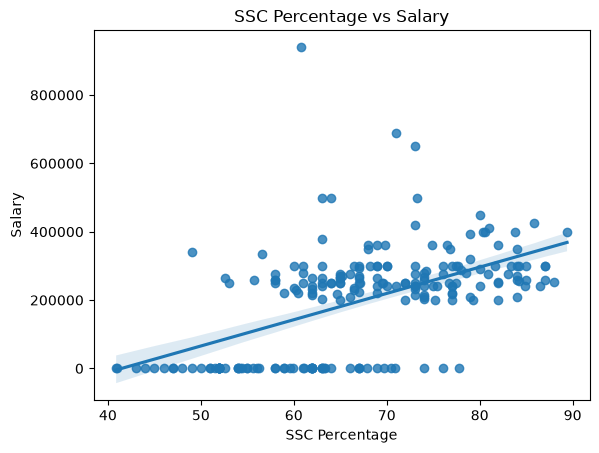

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.regplot(data=dataset, x='ssc_p', y='salary')
plt.title("SSC Percentage vs Salary")
plt.xlabel("SSC Percentage")
plt.ylabel("Salary")
plt.show()

#SSC percentage has a weak positive relationship with salary, indicating that higher SSC percentages are slightly associated with higher salaries.